# Attribution maps of the MEGAN emission change, exact split (LMDI), PD

Same figure as `megan_factor_maps.ipynb` → `PD_<group>_attribution_<season>_*.png` (Δln E split into composition and the MEGAN activity factors), but with the **exact LMDI split** of the branch runs (`analysis/MEGAN_ATTRIBUTION.md` option 1) instead of the grid-cell area-mean factors. Why: `megan-lmdi-vs-approx.ipynb` §6 shows the area-mean split gets composition and γ_L with the wrong sign.

| | Old maps (approx.) | These maps (LMDI) |
|---|---|---|
| Input | processed h0 of CTRL_PD / LCC_PD | `data/processed-data/megan-lmdi/megan_lmdi_PD_<year>.nc` only |
| Years | 2001–2014 (or 2001–2025) | **2001, 2002, 2005, 2006, 2010, 2011** (6 years) |
| Row 1 | Δln E = Δln(f·ε) + Δln γ_eff | Δln E = composition (w·ε) + activity (Σ γ_i) + CLM safeguard |
| Row 2 | Δln γ_eff ≈ Σ Δln γ_i (area means) | activity = Σ γ_i **exactly** |
| Row 3 | residual = weighting + co-variation | — (no residual by construction) |

**Units.** Per cell, LMDI contributions C_f (kg m⁻² s⁻¹) are put in 100·Δln units by 100·Δln E · C_f / ΔE, so the panels add up to 100·Δln E in every cell and year. **Composition** = change of the patch weights w·ε of matched patches (same cell + PFT) + the whole emission of patches present in one run only; not identical to the old f·ε. **CLM safeguard** = steps where CLM sets MEG = 0 because the total γ is outside [0, 100) (+ 'unexplained', which is 0).

Same conventions as the old maps: one colour scale ±60 (PD), cells with CTRL emission < 1 % of the 98th percentile ≥ 45°N masked, under the maps the CTRL-emission-weighted mean 45–90°N ± 95 % t-interval of the 6 yearly means, hatched = not FDR-significant (paired t-test over the 6 years, α_FDR = 0.10), dashed = modified cells. Season means are step-weighted (`nsteps`).

**Caveat (a).** 2001 and 2002 come from the hybrid-start chain, whose months are shifted by one 30-min step (≤ 0.3 % on monthly emissions at a few cells, `megan-lmdi-vs-approx.ipynb` §2); accepted here.

Outputs: `results/figures/megan_factors/PD_<group>_attribution_LMDI_<season>_6yr.png`, table `results/tables/megan_factors/megan_lmdi_attribution_PD_45N.csv`.

## 1. Setup and loading

In [1]:
import sys
from pathlib import Path
REPO = Path("/cluster/home/adelez/BOREAL-FOREST-EXPANSION")
sys.path.insert(0, str(REPO / "src"))
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from IPython.display import display
from boreal_forest_expansion.plotting import megan_maps as mm, forcing_maps as fm
from boreal_forest_expansion.plotting.style import set_default_style

set_default_style()
LMDI_DIR = REPO / "data/processed-data/megan-lmdi"
YEARS = [2001, 2002, 2005, 2006, 2010, 2011]
GROUPS = ["isoprene", "MTERP"]
SEASONS = ["ANN", "JJA"]
LAT_MIN = 45.0
FDR_ALPHA = 0.10
MIN_EMISSION_SHARE = 0.01
GAMMAS = ["gammaL", "gammaT", "gammaP", "gammaA", "gammaC"]
FIG = mm.MEGAN_FIG_DIR
TAB = REPO / "results/tables/megan_factors"
TAB.mkdir(parents=True, exist_ok=True)

TITLE = {
    "dlnE": "EMISSION\nΔln E", "composition": "COMPOSITION\nΔln(w·ε)", "activity": "ACTIVITY\nΣ Δln γ$_i$",
    "safeguard": "CLM SAFEGUARD\nMEG set to 0", "gammaL": "LAI\nΔln γ$_L$", "gammaT": "TEMPERATURE\nΔln γ$_T$",
    "gammaP": "LIGHT\nΔln γ$_P$", "gammaA": "LEAF AGE\nΔln γ$_A$", "gammaC": "CO$_2$\nΔln γ$_C$",
}

lm = {}
for y in YEARS:
    ds = xr.open_dataset(LMDI_DIR / f"megan_lmdi_PD_{y}.nc")[["nsteps", "E_ctrl", "E_lcc", "contribution"]]
    attrs = xr.open_dataset(LMDI_DIR / f"megan_lmdi_PD_{y}.nc").attrs
    ds = ds.assign_coords(compound=attrs["compounds"].split(","), factor=attrs["factors"].split(","),
                          month=ds["month"].values % 100)
    assert attrs["ctrl_case"].startswith("NF2000norbc_tropstratchem_nudg_ctrl_meganpatch"), attrs["ctrl_case"]
    assert attrs["lcc_case"].startswith("NF2000norbc_tropstratchem_nudg_lcc_meganpatch"), attrs["lcc_case"]
    assert list(ds["month"].values) == list(range(1, 13))
    assert "fail" not in attrs["checks"].lower()
    lm[y] = ds.sel(lat=slice(LAT_MIN - 5, None)).load()
    print(y, attrs["ctrl_case"], "/", attrs["lcc_case"])


2001 NF2000norbc_tropstratchem_nudg_ctrl_meganpatch_f19_f19-20261105-from2000 / NF2000norbc_tropstratchem_nudg_lcc_meganpatch_f19_f19-20261105-from2000
2002 NF2000norbc_tropstratchem_nudg_ctrl_meganpatch_f19_f19-20261105-from2000 / NF2000norbc_tropstratchem_nudg_lcc_meganpatch_f19_f19-20261105-from2000
2005 NF2000norbc_tropstratchem_nudg_ctrl_meganpatch_f19_f19-20261105-from2005 / NF2000norbc_tropstratchem_nudg_lcc_meganpatch_f19_f19-20261105-from2005
2006 NF2000norbc_tropstratchem_nudg_ctrl_meganpatch_f19_f19-20261105-from2005 / NF2000norbc_tropstratchem_nudg_lcc_meganpatch_f19_f19-20261105-from2005
2010 NF2000norbc_tropstratchem_nudg_ctrl_meganpatch_f19_f19-20261105-from2010 / NF2000norbc_tropstratchem_nudg_lcc_meganpatch_f19_f19-20261106-from2010
2011 NF2000norbc_tropstratchem_nudg_ctrl_meganpatch_f19_f19-20261105-from2010 / NF2000norbc_tropstratchem_nudg_lcc_meganpatch_f19_f19-20261106-from2010


In [2]:
def season_terms(ds, group, season):
    """Step-weighted season mean; returns 100·Δln E and the terms in the same units (they add up per cell)."""
    w = ds["nsteps"].where(ds["month"].isin(mm.SEASONS[season]), 0).astype(float)
    w = w / w.sum()
    c = ds.sel(compound=[k for k in mm.GROUPS[group]])
    E0 = (c["E_ctrl"].sum("compound") * w).sum("month")
    E1 = (c["E_lcc"].sum("compound") * w).sum("month")
    C = (c["contribution"].sum("compound") * w).sum("month")
    dE, ok = E1 - E0, (E0 > 0) & (E1 > 0)
    with np.errstate(divide="ignore", invalid="ignore"):
        scale = xr.where(abs(dE) > 1e-12 * E0, 100 * np.log(E1 / E0) / dE, 100 / E0)
    t = {"dlnE": 100 * np.log(E1 / E0), "composition": C.sel(factor="composition", drop=True) * scale,
         "safeguard": C.sel(factor=["cutoff", "unexplained"]).sum("factor") * scale}
    for g in GAMMAS:
        t[g] = C.sel(factor=g, drop=True) * scale
    t["activity"] = sum(t[g] for g in GAMMAS)
    return E0, {k: v.where(ok) for k, v in t.items()}

data = {}
for group in GROUPS:
    for season in SEASONS:
        per = [season_terms(lm[y], group, season) for y in YEARS]
        E0 = xr.concat([p[0] for p in per], pd.Index(YEARS, name="year"))
        T = {k: xr.concat([p[1][k] for p in per], pd.Index(YEARS, name="year")) for k in per[0][1]}
        clos = float(abs(T["composition"] + T["activity"] + T["safeguard"] - T["dlnE"]).max())
        print(f"{group:8s} {season}: max |row-1 closure| = {clos:.1e} (100·Δln)")
        assert clos < 1e-8
        data[group, season] = (E0, T)


isoprene ANN: max |row-1 closure| = 3.4e-13 (100·Δln)
isoprene JJA: max |row-1 closure| = 4.5e-13 (100·Δln)
MTERP    ANN: max |row-1 closure| = 3.4e-13 (100·Δln)
MTERP    JJA: max |row-1 closure| = 3.4e-13 (100·Δln)


## 2. Maps

findfont: Failed to find font weight semibold, now using 700.
findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive
findfont: Failed to find font weight semibold, now using 700.


Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/megan_factors/PD_isoprene_attribution_LMDI_ANN_6yr.png


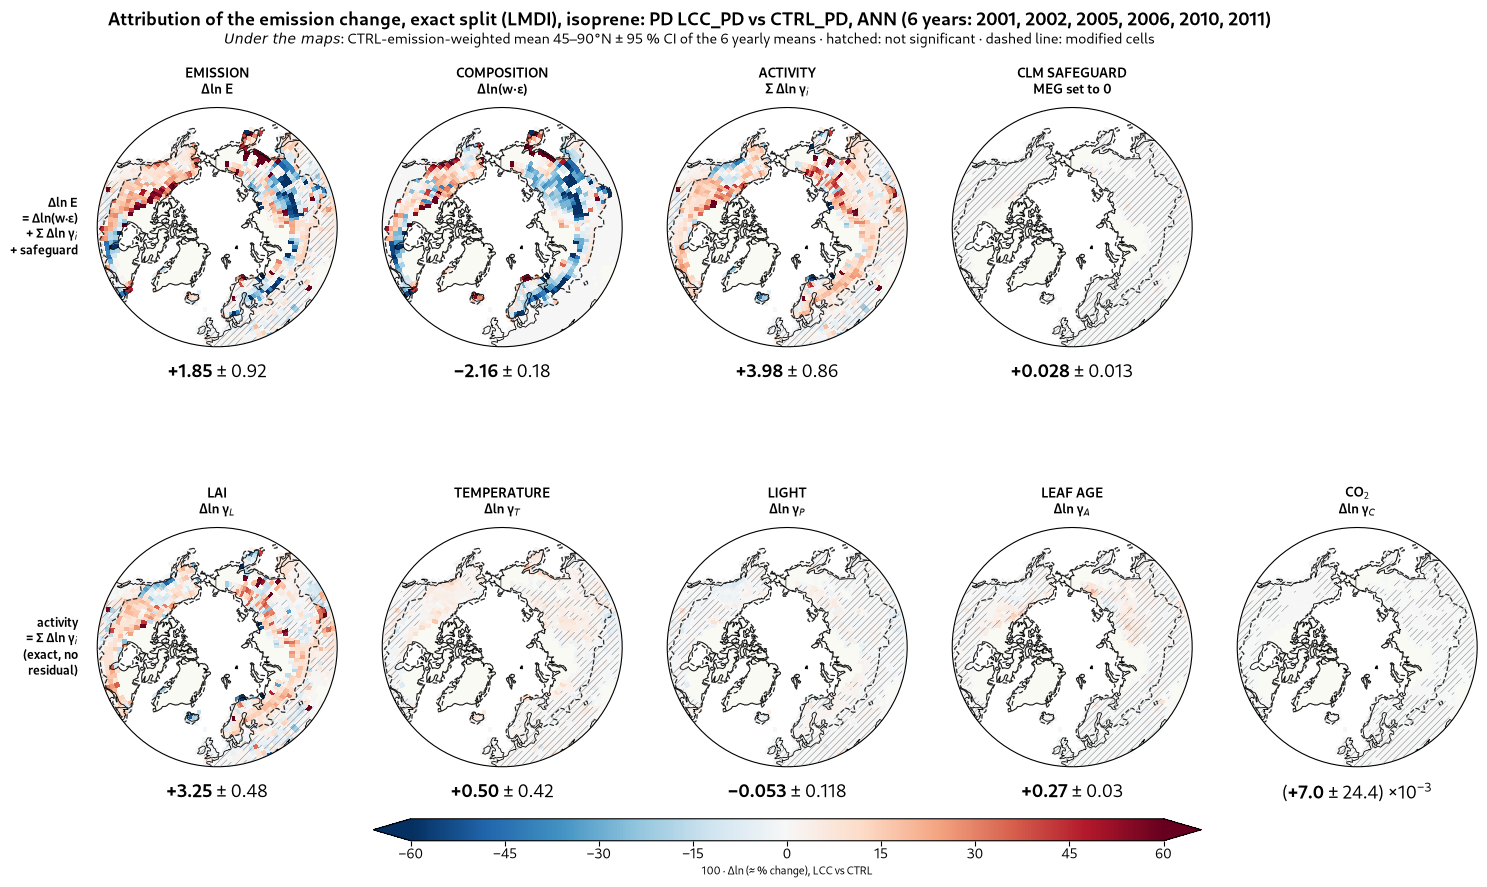

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/megan_factors/PD_isoprene_attribution_LMDI_JJA_6yr.png


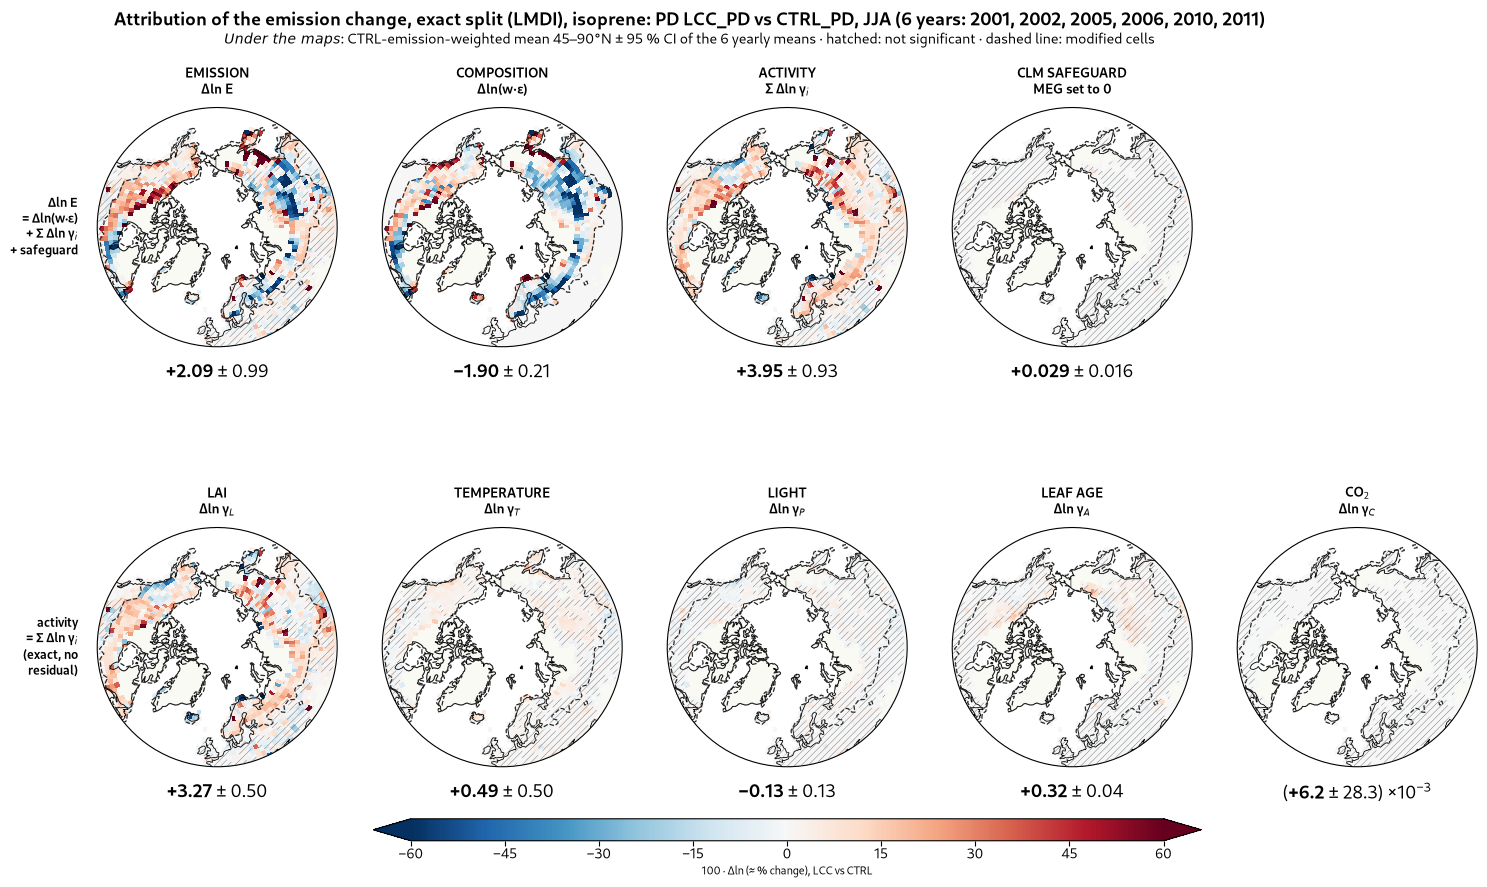

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/megan_factors/PD_MTERP_attribution_LMDI_ANN_6yr.png


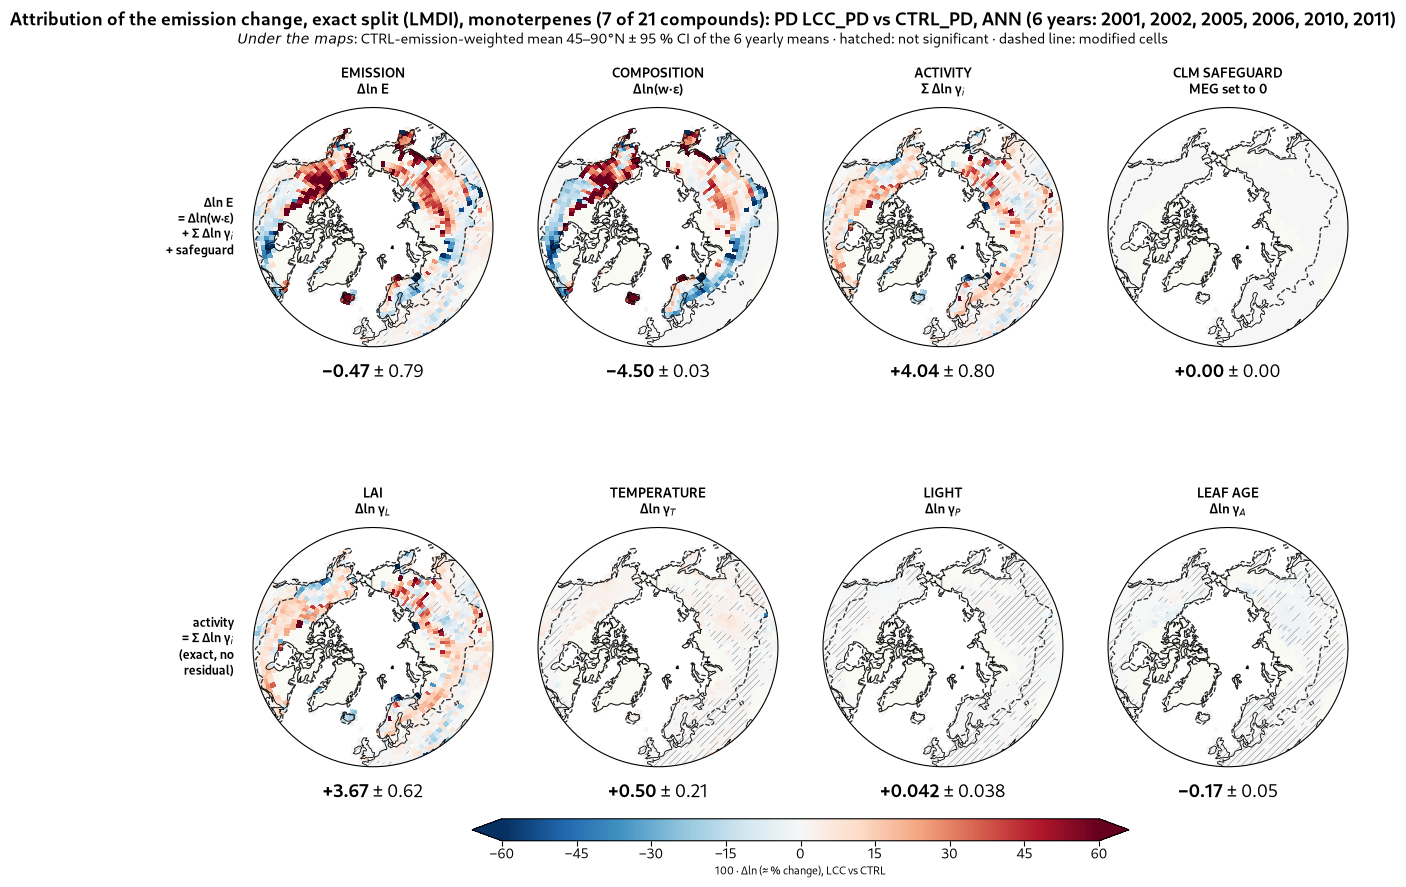

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/megan_factors/PD_MTERP_attribution_LMDI_JJA_6yr.png


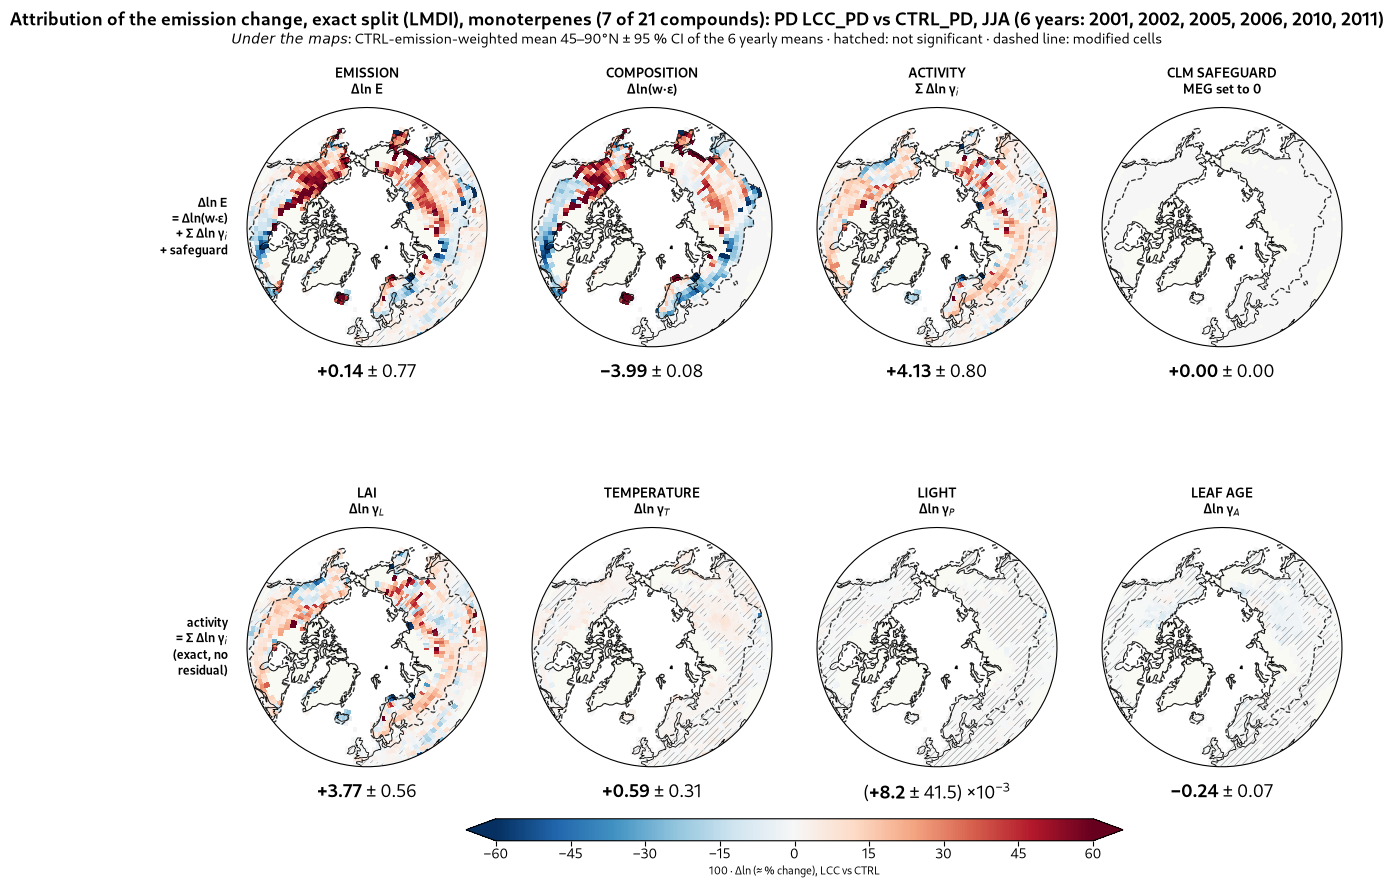

term                     dlnE   composition      activity     safeguard  \
group    season                                                           
MTERP    ANN     -0.47 ± 0.79  -4.50 ± 0.03  +4.04 ± 0.80  +0.00 ± 0.00   
         JJA     +0.14 ± 0.77  -3.99 ± 0.08  +4.13 ± 0.80  +0.00 ± 0.00   
isoprene ANN     +1.85 ± 0.92  -2.16 ± 0.18  +3.98 ± 0.86  +0.03 ± 0.01   
         JJA     +2.09 ± 0.99  -1.90 ± 0.21  +3.95 ± 0.93  +0.03 ± 0.02   

term                   gammaL        gammaT        gammaP        gammaA  \
group    season                                                           
MTERP    ANN     +3.67 ± 0.62  +0.50 ± 0.21  +0.04 ± 0.04  -0.17 ± 0.05   
         JJA     +3.77 ± 0.56  +0.59 ± 0.31  +0.01 ± 0.04  -0.24 ± 0.07   
isoprene ANN     +3.25 ± 0.48  +0.50 ± 0.42  -0.05 ± 0.12  +0.27 ± 0.03   
         JJA     +3.27 ± 0.50  +0.49 ± 0.50  -0.13 ± 0.13  +0.32 ± 0.04   

term                   gammaC  
group    season                
MTERP    ANN              NaN  
         JJA              NaN  
isoprene ANN     +0.01 ± 0.02  
         JJA     +0.01 ± 0.03

In [3]:
v, step = mm.ATTRIBUTION_VMAX["PD"]
norm = mcolors.TwoSlopeNorm(vmin=-v, vcenter=0, vmax=v)
rows_tab = []
for (group, season), (E0, T) in data.items():
    e_ctrl = E0.mean("year")
    thr = MIN_EMISSION_SHARE * float(np.nanquantile(e_ctrl.where(e_ctrl["lat"] >= LAT_MIN).values, 0.98))
    keep = e_ctrl > thr
    w_em = (e_ctrl * np.cos(np.deg2rad(e_ctrl["lat"]))).where(keep, 0)
    mod = mm._modified_mask(e_ctrl)
    gam = [g for g in GAMMAS if group == "isoprene" or g != "gammaC"]
    rows = [["dlnE", "composition", "activity", "safeguard"], gam]
    ncols = max(len(r) for r in rows)
    fig, axes = fm.map_grid(len(rows), ncols, left=2.2, titles_every_row=True)
    for i, keys in enumerate(rows):
        for j in range(ncols):
            if j >= len(keys):
                axes[i, j].set_visible(False)
                continue
            x = T[keys[j]].where(keep)
            m, half = mm._interval(x, w_em, LAT_MIN)
            rows_tab.append(dict(group=group, season=season, term=keys[j], mean=m, ci95=half))
            p = mm._panel(axes[i, j], x.mean("year"), norm, "RdBu_r", TITLE[keys[j]], LAT_MIN,
                          not_sig=mm._not_significant(x, LAT_MIN, FDR_ALPHA), modified=mod,
                          text=fm._format_interval(m, half))
    mm._row_label(axes[0, 0], "Δln E\n= Δln(w·ε)\n+ Σ Δln γ$_i$\n+ safeguard")
    mm._row_label(axes[1, 0], "activity\n= Σ Δln γ$_i$\n(exact, no\nresidual)")
    cb = fm._cbar_below(fig, axes[-1, :], p, "100 · Δln (≈ % change), LCC vs CTRL", fm.CBAR_LABELSIZE_SHARED, shrink=0.6)
    cb.set_ticks(np.arange(-v, v + step / 2, step))
    mm._title(fig, f"Attribution of the emission change, exact split (LMDI), {mm.GROUP_TITLE[group]}: "
                   f"PD LCC_PD vs CTRL_PD, {season} (6 years: {', '.join(map(str, YEARS))})",
              rf"$\mathit{{Under\ the\ maps}}$: CTRL-emission-weighted mean {LAT_MIN:g}–90°N ± 95 % CI of the 6 yearly means"
              " · hatched: not significant · dashed line: modified cells")
    path = FIG / f"PD_{group}_attribution_LMDI_{season}_6yr.png"
    fig.savefig(path, dpi=200, bbox_inches="tight"); print("Saved", path)
    plt.show(); plt.close(fig)

tab = pd.DataFrame(rows_tab)
tab.to_csv(TAB / "megan_lmdi_attribution_PD_45N.csv", index=False)
display(tab.assign(v=lambda t: t["mean"].map("{:+.2f}".format) + " ± " + t["ci95"].map("{:.2f}".format))
           .pivot_table(index=["group", "season"], columns="term", values="v", aggfunc="first")
           .reindex(columns=list(TITLE)))
